# 第 5 章配套 Notebook：视觉图网络：图像切块、矩阵化距离与四大图算子手算对照

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch05_vision_gnn.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-02 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-02/notion/notebooks/ch05_vision_gnn.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有矩阵每一步的中间数值均直接打印并与第 5 章正文手算结果逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 图片怎样变成节点特征矩阵 $X \in \mathbb{R}^{N \times C}$？

复现第 5 章 5.1 节推导与手算例：设输入小彩色图 $I \in \mathbb{R}^{4 \times 4 \times 3}$（高 $H_{\mathrm{img}}=4$、宽 $W_{\mathrm{img}}=4$、RGB 通道 $3$），按 $P \times P = 2 \times 2$ 不重叠切块：
- 节点总数 $N = \frac{4}{2} \times \frac{4}{2} = 4$（对应左耳、右耳、额头、背景 4 个图像块）；
- 每块展平维度 $P^2 \cdot 3 = 12$，拼成块矩阵 $U \in \mathbb{R}^{4 \times 12}$；
- 右乘切块嵌入（Patch Stem）权重 $W_{\mathrm{stem}} \in \mathbb{R}^{12 \times 2}$，得到节点特征矩阵 $X = U W_{\mathrm{stem}} \in \mathbb{R}^{4 \times 2}$。

同时验证：**“不重叠切块展平再右乘 $W_{\mathrm{stem}}$”** 与 **“核大小 $P\times P$、步幅为 $P$ 的二维卷积”** 在数学上逐位恒等！

In [2]:
# 构造一张 4x4x3 的玩具图像 I（整数像素便于核对）
rng = np.random.default_rng(42)
I_img = rng.integers(0, 5, size=(4, 4, 3)).astype(float)
H_img, W_img, C_in = I_img.shape
P = 2  # patch 大小 2x2
C_out = 2

# 方法 A：显式切出 N=4 个 2x2x3 图像块，展平为 U (4, 12)，再右乘 W_stem (12, 2)
patches = []
for r in range(0, H_img, P):
    for c in range(0, W_img, P):
        patch = I_img[r:r+P, c:c+P, :]  # (2, 2, 3)
        patches.append(patch.reshape(-1))  # (12,)
U = np.stack(patches, axis=0)  # (N=4, 12)
W_stem = rng.normal(0.0, 0.5, size=(P * P * C_in, C_out)).round(2)

X_patch_mm = U @ W_stem  # (4, 2)

# 方法 B：直接按核 (2, 2, 3, 2)、步幅 stride=2 做二维滑动窗口卷积再展平空间维
K_conv = W_stem.reshape(P, P, C_in, C_out)
conv_map = np.zeros((H_img // P, W_img // P, C_out))
for i in range(H_img // P):
    for j in range(W_img // P):
        window = I_img[i*P:(i+1)*P, j*P:(j+1)*P, :]  # (2, 2, 3)
        for ch in range(C_out):
            conv_map[i, j, ch] = np.sum(window * K_conv[:, :, :, ch])
X_conv_stride = conv_map.reshape(-1, C_out)

print("输入图像 I.shape          =", I_img.shape)
print("展平块矩阵 U.shape        =", U.shape, "(N=4 个节点，每块 12 个像素值)")
print("投影权重 W_stem.shape     =", W_stem.shape)
print("节点特征矩阵 X.shape      =", X_patch_mm.shape, "(N=4, C=2)")
print("X (切块矩阵乘) =\n", X_patch_mm)
print("切块矩阵乘 vs 步幅卷积最大误差:", np.max(np.abs(X_patch_mm - X_conv_stride)))
assert np.allclose(X_patch_mm, X_conv_stride)


输入图像 I.shape          = (4, 4, 3)
展平块矩阵 U.shape        = (4, 12) (N=4 个节点，每块 12 个像素值)
投影权重 W_stem.shape     = (12, 2)
节点特征矩阵 X.shape      = (4, 2) (N=4, C=2)
X (切块矩阵乘) =
 [[ 3.13  3.34]
 [ 2.85  2.26]
 [ 3.8   0.54]
 [ 0.92 -2.01]]
切块矩阵乘 vs 步幅卷积最大误差: 4.440892098500626e-16


## 2. 两两平方欧氏距离矩阵写法与手算例 5.1 完整复现

对节点特征矩阵 $X \in \mathbb{R}^{4 \times 2}$：
$$X = \begin{bmatrix} 2 & 0 \\ 3 & 1 \\ 0 & 2 \\ -1 & -2 \end{bmatrix}$$
验证恒等式 $D_{ij} = \lVert \mathbf{x}_i - \mathbf{x}_j \rVert_2^2 = \lVert \mathbf{x}_i \rVert_2^2 + \lVert \mathbf{x}_j \rVert_2^2 - 2\mathbf{x}_i^\top \mathbf{x}_j$，即矩阵形式：
$$D = \mathbf{q}\mathbf{1}_N^\top + \mathbf{1}_N\mathbf{q}^\top - 2 X X^\top$$
其中 $q_i = \lVert \mathbf{x}_i \rVert_2^2 = \sum_{c=1}^C X_{ic}^2$。并补充验证 ViG 官方代码 `torch_edge.py` 先做通道 $\ell_2$ 归一化时，$\lVert \hat{\mathbf{x}}_i - \hat{\mathbf{x}}_j \rVert_2^2 = 2 - 2\cos(\mathbf{x}_i, \mathbf{x}_j)$。

In [3]:
X = np.array([
    [ 2.0,  0.0],  # 节点 1（左耳）
    [ 3.0,  1.0],  # 节点 2（右耳）
    [ 0.0,  2.0],  # 节点 3（额头）
    [-1.0, -2.0],  # 节点 4（背景）
])
N, C = X.shape

# 1) 矩阵公式一次算出 D = q 1^T + 1 q^T - 2 X X^T
q = np.sum(X ** 2, axis=1, keepdims=True)  # shape (4, 1): [[4], [10], [4], [5]]
G = X @ X.T                                # Gram 矩阵 X X^T, shape (4, 4)
D_mat = q + q.T - 2.0 * G                  # 广播等价于 q @ 1^T + 1 @ q^T - 2 G

# 2) 双重循环逐对验证 ||x_i - x_j||_2^2
D_loop = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        D_loop[i, j] = np.sum((X[i] - X[j]) ** 2)

print("节点平方范数向量 q^T =", q.ravel())
print("内积矩阵 G = X X^T =\n", G)
print("两两平方距离矩阵 D =\n", D_mat)
assert np.allclose(D_mat, D_loop)
assert np.allclose(D_mat, np.array([
    [ 0.,  2.,  8., 13.],
    [ 2.,  0., 10., 25.],
    [ 8., 10.,  0., 17.],
    [13., 25., 17.,  0.],
]))

# 3) 补充验证 ViG 代码里的通道 L2 归一化等价于余弦距离 2 - 2 cos(x_i, x_j)
X_norm = X / np.linalg.norm(X, axis=1, keepdims=True)
D_norm_mat = 2.0 - 2.0 * (X_norm @ X_norm.T)
D_norm_loop = np.sum((X_norm[:, None, :] - X_norm[None, :, :]) ** 2, axis=-1)
assert np.allclose(D_norm_mat, D_norm_loop)
print("\n通道 L2 归一化后的平方距离矩阵 (等于 2 - 2*cos):\n", np.round(D_norm_mat, 4))


节点平方范数向量 q^T = [ 4. 10.  4.  5.]
内积矩阵 G = X X^T =
 [[ 4.  6.  0. -2.]
 [ 6. 10.  2. -5.]
 [ 0.  2.  4. -4.]
 [-2. -5. -4.  5.]]
两两平方距离矩阵 D =
 [[ 0.  2.  8. 13.]
 [ 2.  0. 10. 25.]
 [ 8. 10.  0. 17.]
 [13. 25. 17.  0.]]

通道 L2 归一化后的平方距离矩阵 (等于 2 - 2*cos):
 [[0.     0.1026 2.     2.8944]
 [0.1026 0.     1.3675 3.4142]
 [2.     1.3675 0.     3.7889]
 [2.8944 3.4142 3.7889 0.    ]]


## 3. ViG 的 `max-relative` 聚合手算复现：为什么差值可正可负、按通道独立取最大？

在手算例 5.1 的 $X$ 上取 $k=2$ 个最近邻：
1. **不含自环邻域 $\mathcal{N}(i)$**（对应论文正文“找 $K$ 个最近邻”或 Pyramid ViG 跨尺度池化邻域 $\mathbf{y}_j - \mathbf{x}_i$）：观察**节点 2** $([3, 1])$——它的两个邻居是节点 1 $([2, 0])$ 和节点 3 $([0, 2])$，差值分别为 $[-1, -1]$ 与 $[-3, +1]$，逐通道取最大得到 $\mathbf{m}_2 = [-1, +1]$：**第 1 通道严格为负（`-1.0`），第 2 通道严格为正（`+1.0`）**！
2. **含自环邻域 $\tilde{\mathcal{N}}(i) = \mathcal{N}(i) \cup \{i\}$**（对应各向同性 ViG 代码 `topk(-dist, k)` 把自身距离 `0` 选为第 1 个邻居）：自身差 $\mathbf{x}_i - \mathbf{x}_i = \mathbf{0}$ 会把所有负差值下界托底到 `0`，但候选差值本身依然有正有负，且拼接 $[\mathbf{x}_i \,\|\, \mathbf{m}_i]$ 后直接送入线性层 $W_{\mathrm{update}}$（中间没有 ReLU）。

In [4]:
k = 2

# 情形 A：不含自环的 k=2 最近邻（先把对角线设为 +inf 再 argsort）
D_no_self = D_mat.copy()
np.fill_diagonal(D_no_self, np.inf)
knn_no_self = np.argsort(D_no_self, axis=1)[:, :k]  # shape (4, 2)

print("=== 情形 A：不含自环 k=2 邻域 N(i) ===")
M_vig_no_self = np.zeros_like(X)
for i in range(N):
    nbrs = knn_no_self[i]
    diffs = X[nbrs] - X[i]  # (k=2, C=2)，邻居减自身 x_j - x_i
    M_vig_no_self[i] = np.max(diffs, axis=0)
    print(f"节点 {i+1} (x={X[i]}): 邻居下标={nbrs+1}")
    for idx_n, diffs_row in zip(nbrs, diffs):
        print(f"    x_{idx_n+1} - x_{i+1} = {X[idx_n]} - {X[i]} = {diffs_row}")
    print(f"  -> 逐通道 max m_{i+1} = {M_vig_no_self[i]}")

assert np.allclose(M_vig_no_self, np.array([
    [ 1.,  2.],
    [-1.,  1.],  # 注意第 1 通道为 -1.0 < 0！
    [ 3., -1.],  # 注意第 2 通道为 -1.0 < 0！
    [ 3.,  4.],
]))

# 拼接 [x_i || m_i] 并右乘 W_update (2C x C_out = 4 x 2)，对应 ViG Eq. (3)-(4)
X_concat = np.concatenate([X, M_vig_no_self], axis=1)  # shape (4, 4)
W_update = np.array([
    [ 1.0,  0.0],
    [ 0.0,  1.0],
    [ 0.5, -0.5],
    [-0.5,  0.5],
])
X_vig_out = X_concat @ W_update
print("\n拼接矩阵 X'' = [X || M] (shape 4x4):\n", X_concat)
print("线性更新后 X' = X'' @ W_update (shape 4x2):\n", X_vig_out)

# 情形 B：含自环的 k=2 最近邻（自身距离 0 占掉 1 个名额，再加最近 1 个他节点）
knn_with_self = np.argsort(D_mat, axis=1)[:, :k]
M_vig_with_self = np.max(X[knn_with_self] - X[:, None, :], axis=1)
print("\n=== 情形 B：含自环 k=2 邻域（自身差 0 把负值托底为 0）===\n", M_vig_with_self)


=== 情形 A：不含自环 k=2 邻域 N(i) ===
节点 1 (x=[2. 0.]): 邻居下标=[2 3]
    x_2 - x_1 = [3. 1.] - [2. 0.] = [1. 1.]
    x_3 - x_1 = [0. 2.] - [2. 0.] = [-2.  2.]
  -> 逐通道 max m_1 = [1. 2.]
节点 2 (x=[3. 1.]): 邻居下标=[1 3]
    x_1 - x_2 = [2. 0.] - [3. 1.] = [-1. -1.]
    x_3 - x_2 = [0. 2.] - [3. 1.] = [-3.  1.]
  -> 逐通道 max m_2 = [-1.  1.]
节点 3 (x=[0. 2.]): 邻居下标=[1 2]
    x_1 - x_3 = [2. 0.] - [0. 2.] = [ 2. -2.]
    x_2 - x_3 = [3. 1.] - [0. 2.] = [ 3. -1.]
  -> 逐通道 max m_3 = [ 3. -1.]
节点 4 (x=[-1. -2.]): 邻居下标=[1 3]
    x_1 - x_4 = [2. 0.] - [-1. -2.] = [3. 2.]
    x_3 - x_4 = [0. 2.] - [-1. -2.] = [1. 4.]
  -> 逐通道 max m_4 = [3. 4.]

拼接矩阵 X'' = [X || M] (shape 4x4):
 [[ 2.  0.  1.  2.]
 [ 3.  1. -1.  1.]
 [ 0.  2.  3. -1.]
 [-1. -2.  3.  4.]]
线性更新后 X' = X'' @ W_update (shape 4x2):
 [[ 1.5  0.5]
 [ 2.   2. ]
 [ 2.   0. ]
 [-1.5 -1.5]]

=== 情形 B：含自环 k=2 邻域（自身差 0 把负值托底为 0）===
 [[1. 1.]
 [0. 0.]
 [2. 0.]
 [3. 2.]]


## 4. 四种视觉图算子横向对照：ViG vs DGCNN vs MobileViG vs ST-GCN

用简洁的 NumPy 代码把四类代表算子放在一起对比：
1. **DGCNN 的 `EdgeConv`**（Wang 等 2019 Eq. 7–9）：在**每一条边 $(i,j)$** 上先算线性投影加非线性 $\mathbf{e}_{ij}' = \mathrm{ReLU}(\Theta(\mathbf{x}_j - \mathbf{x}_i) + \Phi \mathbf{x}_i)$，**最后**再对邻居取逐通道 `max`（边级 MLP 算力为节点级的 $k$ 倍）。
2. **MobileViG 的 `SVGA`**（Munir 等 2023 Algorithm 1）：在 $4\times 4$ 网格、步长 $K=2$ 上用固定循环平移 `np.roll` 代替动态 $k$-NN，注意它的差值方向是 **`X - roll(X)`（自身减邻居，与 ViG 相反！）**，且 $m=0$ 平移量为 0 时自带 `X - X = 0`。
3. **ST-GCN 的空间骨架图卷积**（Yan 等 2018 Eq. 4–5）：图和邻域子集划分 $k \in \{0,1,2\}$ 完全固定，纯矩阵乘加 $\sum_{k=0}^{K-1} \hat{A}_k X W_k$，没有任何动态选边或 `max`。

In [5]:
# 1) DGCNN EdgeConv (含自环 k=3，即自身 + 2 个最近他节点，与情形 A 覆盖相同邻居边)
knn_dgcnn = np.argsort(D_mat, axis=1)[:, :3]  # 含自身共 3 条边
# 设输出通道 M=2，边函数参数 Theta (2x2) 作用于 (x_j - x_i)，Phi (2x2) 作用于 x_i
Theta = np.array([[ 0.5, -0.5],
                  [-0.5,  0.5]])  # shape (C_in=2, M=2)
Phi   = np.array([[ 1.0,  0.0],
                  [ 0.0,  1.0]])  # shape (C_in=2, M=2)

X_dgcnn_out = np.zeros((N, 2))
for i in range(N):
    nbrs = knn_dgcnn[i]
    # 每条边先过线性 + ReLU: shape (3, 2)
    edge_pre = (X[nbrs] - X[i]) @ Theta + X[i] @ Phi
    edge_feat = np.maximum(0.0, edge_pre)  # 论文 Eq. 8 用 ReLU（官方代码用 LeakyReLU(0.2)）
    X_dgcnn_out[i] = np.max(edge_feat, axis=0)
print("1) DGCNN EdgeConv 输出 (每条边先过 MLP+ReLU 再取 max):\n", X_dgcnn_out)

# 2) MobileViG SVGA (Algorithm 1): 在 4x4 单通道特征图、连接步距 K=2 上演示固定循环平移
F_grid = np.array([
    [1., 5., 3., 2.],
    [4., 2., 6., 1.],
    [7., 0., 2., 8.],
    [3., 4., 1., 5.],
])  # H=4, W=4
H_g, W_g = F_grid.shape
K_step = 2
Xj = np.zeros_like(F_grid)  # m=0 时 X - roll(X, 0) = 0，故初值等价于全 0

m = 0
while m * K_step < H_g:
    Xc = F_grid - np.roll(F_grid, shift=m * K_step, axis=0)  # 自身减纵向平移邻居！
    Xj = np.maximum(Xc, Xj)
    m += 1

m = 0
while m * K_step < W_g:
    Xr = F_grid - np.roll(F_grid, shift=m * K_step, axis=1)  # 自身减横向平移邻居！
    Xj = np.maximum(Xr, Xj)
    m += 1

# 验证左上角像素 (0,0)=1 的固定连接邻居是 (2,0)=7 和 (0,2)=3：
# 自身减邻居分别为 1-7=-6, 1-3=-2，与自身差 0 取 max 得 0；
# 而像素 (2,0)=7 连到 (0,0)=1 和 (2,2)=2：自身减邻居为 7-1=6, 7-2=5，取 max 得 6！
print("\n2) MobileViG SVGA 固定平移 max-relative 特征 Xj (注意方向是 x_i - x_j):\n", Xj)
assert Xj[0, 0] == 0.0 and Xj[2, 0] == 6.0

# 3) ST-GCN 固定骨架分区求和：设 4 个关节链 1-2-3-4，分为 k=0(自身) 与 k=1(骨连接邻居) 两个固定子集
A_self = np.eye(4)
A_nbr = np.array([
    [0., 1., 0., 0.],
    [0.5, 0., 0.5, 0.],  # 按子集基数 Z_{ti} 归一化
    [0., 0.5, 0., 0.5],
    [0., 0., 1., 0.],
])
X_stgcn_out = A_self @ X @ Phi + A_nbr @ X @ Theta
print("\n3) ST-GCN 固定子集线性加权输出 (无 kNN、无 max):\n", X_stgcn_out)


1) DGCNN EdgeConv 输出 (每条边先过 MLP+ReLU 再取 max):
 [[2. 2.]
 [3. 3.]
 [2. 2.]
 [0. 0.]]

2) MobileViG SVGA 固定平移 max-relative 特征 Xj (注意方向是 x_i - x_j):
 [[0. 5. 2. 0.]
 [1. 1. 5. 0.]
 [6. 0. 0. 8.]
 [2. 2. 0. 4.]]

3) ST-GCN 固定子集线性加权输出 (无 kNN、无 max):
 [[ 3.   -1.  ]
 [ 3.    1.  ]
 [ 0.75  1.25]
 [-2.   -1.  ]]


## 5. 可视化：动态 $k$-NN 图连接与节点相对差向量

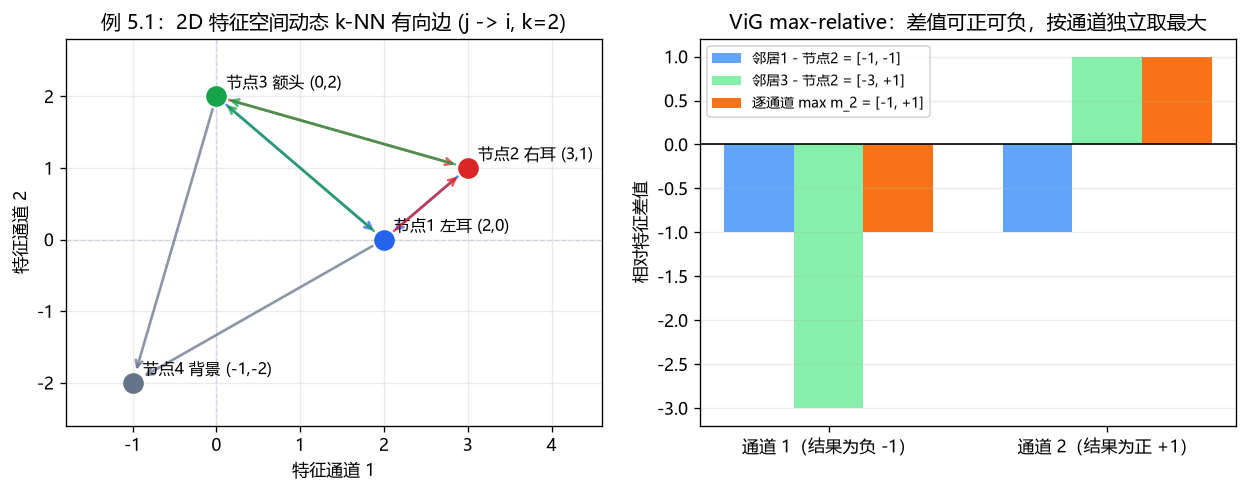

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=120)

# 左图：2D 特征空间中的 4 个节点与 k=2（不含自环）有向近邻连边
ax = axes[0]
labels = ["节点1 左耳 (2,0)", "节点2 右耳 (3,1)", "节点3 额头 (0,2)", "节点4 背景 (-1,-2)"]
colors = ["#2563eb", "#dc2626", "#16a34a", "#64748b"]
for i in range(N):
    for j in knn_no_self[i]:
        ax.annotate(
            "", xy=X[i], xytext=X[j],
            arrowprops=dict(arrowstyle="->", color=colors[i], lw=1.6, alpha=0.75, shrinkA=8, shrinkB=8),
        )
    ax.scatter(X[i, 0], X[i, 1], s=130, color=colors[i], zorder=5)
    ax.text(X[i, 0] + 0.12, X[i, 1] + 0.12, labels[i], fontsize=9.5)
ax.axhline(0, color="#cbd5e1", lw=0.8, ls="--")
ax.axvline(0, color="#cbd5e1", lw=0.8, ls="--")
ax.set_xlim(-1.8, 4.6)
ax.set_ylim(-2.6, 2.8)
ax.set_title("例 5.1：2D 特征空间动态 k-NN 有向边 (j -> i, k=2)")
ax.set_xlabel("特征通道 1")
ax.set_ylabel("特征通道 2")
ax.grid(True, alpha=0.25)

# 右图：节点 2 的两条相对差向量与逐通道 max 结果 [-1, +1]
ax2 = axes[1]
bars_x = np.arange(2)
w = 0.25
diff_12 = X[0] - X[1]  # [-1, -1]
diff_32 = X[2] - X[1]  # [-3, +1]
m_2 = M_vig_no_self[1] # [-1, +1]
ax2.bar(bars_x - w, diff_12, width=w, label="邻居1 - 节点2 = [-1, -1]", color="#60a5fa")
ax2.bar(bars_x,     diff_32, width=w, label="邻居3 - 节点2 = [-3, +1]", color="#86efac")
ax2.bar(bars_x + w, m_2,     width=w, label="逐通道 max m_2 = [-1, +1]", color="#f97316")
ax2.axhline(0, color="black", lw=1.0)
ax2.set_xticks(bars_x, ["通道 1（结果为负 -1）", "通道 2（结果为正 +1）"])
ax2.set_ylabel("相对特征差值")
ax2.set_title("ViG max-relative：差值可正可负，按通道独立取最大")
ax2.legend(fontsize=8.5)
ax2.grid(True, axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
